In [83]:
# Basic
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from glob import glob
from tqdm import tqdm

# ML / DL
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Utils
from sklearn.model_selection import train_test_split
import torchvision.models as models


In [84]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

IMG_SIZE   = 256
BATCH_SIZE = 8
EPOCHS     = 30
LR         = 1e-3

TRAIN_IMG_DIR  = "dataset/train/images"
TRAIN_MASK_DIR = "dataset/train/mask"
TEST_IMG_DIR   = "dataset/test/images"

# EDA

In [85]:
img_paths  = sorted(glob(f"{TRAIN_IMG_DIR}/*"))
mask_paths = sorted(glob(f"{TRAIN_MASK_DIR}/*"))

print("Images:", len(img_paths))
print("Masks :", len(mask_paths))


Images: 498
Masks : 498


In [86]:
def show_sample(img_path, mask_path):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    overlay = img.copy()
    overlay[mask > 0] = [255, 0, 0]

    plt.figure(figsize=(15,5))
    plt.subplot(1,3,1); plt.title("Image");   plt.imshow(img);     plt.axis("off")
    plt.subplot(1,3,2); plt.title("Mask");    plt.imshow(mask, cmap="gray"); plt.axis("off")
    plt.subplot(1,3,3); plt.title("Overlay"); plt.imshow(overlay); plt.axis("off")
    plt.show()


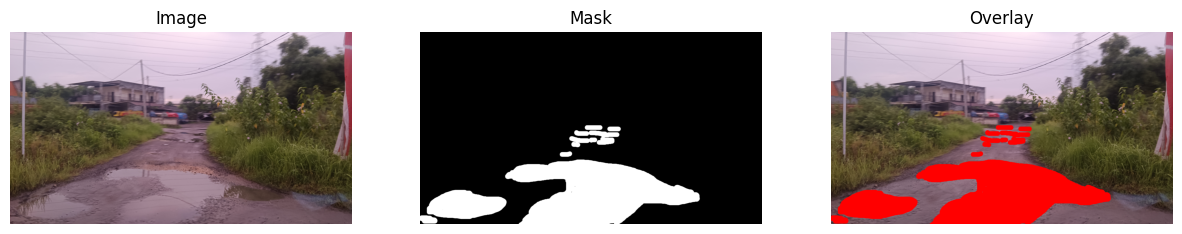

In [87]:
show_sample(img_paths[0], mask_paths[0])


# DATALOAD

In [88]:
class RoadDataset(Dataset):
    def __init__(self, img_paths, mask_paths=None, augment=False):
        self.img_paths = img_paths
        self.mask_paths = mask_paths
        self.augment = augment

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img = cv2.imread(self.img_paths[idx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        mask = None
        if self.mask_paths is not None:
            mask = cv2.imread(self.mask_paths[idx], cv2.IMREAD_GRAYSCALE)

        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        if mask is not None:
            mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE),
                              interpolation=cv2.INTER_NEAREST)

        # ===== Augmentation (TRAIN ONLY) =====
        if self.augment:
            if np.random.rand() > 0.5:
                img = np.fliplr(img)
                if mask is not None:
                    mask = np.fliplr(mask)

            if np.random.rand() > 0.5:
                factor = 1 + np.random.uniform(-0.2, 0.2)
                img = np.clip(img * factor, 0, 255)

        # Normalize
        img = img / 255.0
        img = torch.tensor(img, dtype=torch.float).permute(2,0,1)

        if mask is not None:
            mask = (mask > 0).astype(np.float32)
            mask = torch.tensor(mask).unsqueeze(0)

        return img, mask


In [89]:
train_imgs, val_imgs, train_masks, val_masks = train_test_split(
    img_paths, mask_paths, test_size=0.2, random_state=42
)

train_ds = RoadDataset(train_imgs, train_masks, augment=True)
val_ds   = RoadDataset(val_imgs, val_masks, augment=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)


# MODELS 

In [90]:
class DoubleConv(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


In [91]:
class UNetResNet(nn.Module):
    def __init__(self):
        super().__init__()
        base = models.resnet34(weights=models.ResNet34_Weights.DEFAULT)

        self.enc1 = nn.Sequential(base.conv1, base.bn1, base.relu)
        self.enc2 = base.layer1
        self.enc3 = base.layer2
        self.enc4 = base.layer3
        self.enc5 = base.layer4

        self.up4  = nn.ConvTranspose2d(512, 256, 2, 2)
        self.dec4 = DoubleConv(512, 256)

        self.up3  = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec3 = DoubleConv(256, 128)

        self.up2  = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec2 = DoubleConv(128, 64)

        self.up1  = nn.ConvTranspose2d(64, 64, 2, 2)
        # self.dec1 = DoubleConv(128, 64)

        self.out = nn.Conv2d(64, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        e5 = self.enc5(e4)

        d4 = self.dec4(torch.cat([self.up4(e5), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        # d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        d1 = self.up1(d2) 
        out = self.out(d1)

        # return self.out(d1)
        return out


# LOSS FUNCTION

In [92]:
bce = nn.BCEWithLogitsLoss()

def dice_loss(pred, target, smooth=1.):
    pred = torch.sigmoid(pred)
    intersection = (pred * target).sum()
    union = pred.sum() + target.sum()
    return 1 - (2. * intersection + smooth) / (union + smooth)

def combo_loss(pred, target):
    return bce(pred, target) + dice_loss(pred, target)


# TRAINING & VALIDATION

In [93]:
model = UNetResNet().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)


In [94]:
def train_epoch(loader):
    model.train()
    total_loss = 0

    for img, mask in loader:
        img  = img.to(DEVICE)
        mask = mask.to(DEVICE)

        optimizer.zero_grad()
        pred = model(img)
        loss = combo_loss(pred, mask)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)


In [95]:
def validate(loader):
    model.eval()
    total_loss = 0

    with torch.no_grad():
        for img, mask in loader:
            img  = img.to(DEVICE)
            mask = mask.to(DEVICE)

            pred = model(img)
            loss = combo_loss(pred, mask)
            total_loss += loss.item()

    return total_loss / len(loader)


# TRAINING EXECUTION

In [96]:
x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
y = model(x)
print(y.shape)


torch.Size([1, 1, 256, 256])


In [97]:
for epoch in range(EPOCHS):
    train_loss = train_epoch(train_loader)
    val_loss   = validate(val_loader)

    print(f"Epoch {epoch+1}/{EPOCHS} | "
          f"Train: {train_loss:.4f} | Val: {val_loss:.4f}")


Epoch 1/30 | Train: 1.0204 | Val: 1.8090
Epoch 2/30 | Train: 0.7575 | Val: 1.2631
Epoch 3/30 | Train: 0.6858 | Val: 0.7355
Epoch 4/30 | Train: 0.6401 | Val: 0.6778
Epoch 5/30 | Train: 0.6007 | Val: 0.6754
Epoch 6/30 | Train: 0.6272 | Val: 0.5726
Epoch 7/30 | Train: 0.5530 | Val: 0.6226
Epoch 8/30 | Train: 0.5378 | Val: 0.5654
Epoch 9/30 | Train: 0.5316 | Val: 0.5939
Epoch 10/30 | Train: 0.5214 | Val: 0.6410
Epoch 11/30 | Train: 0.4980 | Val: 0.7765
Epoch 12/30 | Train: 0.4658 | Val: 0.5380
Epoch 13/30 | Train: 0.4277 | Val: 0.5645
Epoch 14/30 | Train: 0.4306 | Val: 0.6634
Epoch 15/30 | Train: 0.4487 | Val: 0.5277
Epoch 16/30 | Train: 0.4128 | Val: 0.5921
Epoch 17/30 | Train: 0.4052 | Val: 0.5815
Epoch 18/30 | Train: 0.3840 | Val: 0.5679
Epoch 19/30 | Train: 0.3643 | Val: 0.5138
Epoch 20/30 | Train: 0.3700 | Val: 0.5134
Epoch 21/30 | Train: 0.3498 | Val: 0.5493
Epoch 22/30 | Train: 0.3559 | Val: 0.5714
Epoch 23/30 | Train: 0.3373 | Val: 0.5316
Epoch 24/30 | Train: 0.3380 | Val: 0.5809
E

# INFERENCE

In [98]:
test_imgs = sorted(glob(f"{TEST_IMG_DIR}/*"))
test_ds   = RoadDataset(test_imgs, mask_paths=None, augment=False)
test_loader = DataLoader(test_ds, batch_size=1, shuffle=False)

In [99]:
model.eval()
pred_masks = []

with torch.no_grad():
    for img, _ in tqdm(test_loader):
        img = img.to(DEVICE)
        pred = torch.sigmoid(model(img))
        pred = (pred > 0.5).float()
        pred_masks.append(pred.cpu().numpy()[0,0])


  0%|          | 0/295 [00:00<?, ?it/s]


TypeError: default_collate: batch must contain tensors, numpy arrays, numbers, dicts or lists; found <class 'NoneType'>

# ENCODE

In [ ]:
def encode_rle(mask):
    pixels = mask.T.flatten()
    pixels = np.concatenate([[0], pixels, [0]])
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1
    runs[1::2] -= runs[0::2]
    return " ".join(str(x) for x in runs)


# SUBMIT

In [ ]:
submission = []

for path, mask in zip(test_imgs, pred_masks):
    img_id = os.path.basename(path)
    rle    = encode_rle(mask)
    submission.append([img_id, rle])

df = pd.DataFrame(submission, columns=["image_id", "rle_mask"])
df.to_csv("submission.csv", index=False)
